# Data cleaning 




In [4]:
import sys
from pathlib import Path

roots = [Path.cwd(), *Path.cwd().parents]
project = next((p for root in roots for p in (root, root / "epfl_ml_p1")
                if (p / "p1" / "cleaning.py").is_file()), None)
if project is None:
    raise FileNotFoundError("Open this notebook from epfl_ml_p1 or its parent folder")
sys.path.insert(0, str(project))

In [5]:
import numpy as np
import matplotlib.pyplot as plt
RAW_DATA_DIR = project / "data/raw"
INTERIM_DATA_DIR = project / "data/interim"
from p1.cache import cached_raw, cached_clean
from p1.training import split_rows

CACHE = INTERIM_DATA_DIR / "fd_cleaning"
x_train, x_test, y, train_ids, test_ids, names = cached_raw(RAW_DATA_DIR, CACHE)
y = (y == 1).astype(int)
print(x_train.shape, x_test.shape, f"{y.mean():.1%} positive labels")

Raw data: cache hit
(328135, 321) (109379, 321) 8.8% positive labels


## Missing answers

Blank ≠ zero. Some questions are skipped or only asked in certain states.

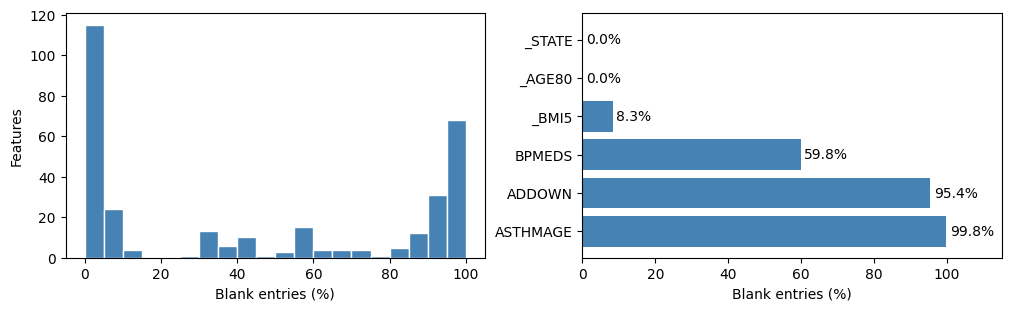

In [6]:
missing = np.isnan(x_train).mean(axis=0)
examples = ["_STATE", "_AGE80", "_BMI5", "BPMEDS", "ADDOWN", "ASTHMAGE"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
axes[0].hist(100 * missing, bins=20, color="steelblue", edgecolor="white")
axes[0].set(xlabel="Blank entries (%)", ylabel="Features")
rates = [100 * missing[names.index(n)] for n in examples]
axes[1].barh(examples, rates, color="steelblue")
axes[1].set(xlabel="Blank entries (%)", xlim=(0, 115))
axes[1].invert_yaxis()
for i, rate in enumerate(rates):
    axes[1].text(rate + 1, i, f"{rate:.1f}%", va="center")
plt.show()

## Field rules

Information regarding the dataset : [CDC 2015 data page](https://www.cdc.gov/brfss/annual_data/annual_2015.html), which provides the [codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf).

An AI agent used the codebook to draft categorical/numeric types and special response codes in `cleaning_schema.json`.

- `_STATE`: category, not a quantity. One-hot encode it.
- Age: years, capped at 80. Weight: kg. Height: metres. BMI: kg/m².
- Special codes vary: 88 can mean zero days; 98 can mean zero work hours.

- `ASTHMAGE=97`: age ≤10, not age 97. `CHKHEMO3=98`: never heard of the test. Keep these as response flags, not exact measurements.

## Clean


Drop fields above 50% unavailable.<br>
Numeric gaps → training mean + missing flag. <br>
Categorical gaps → separate category (onehot). <br>
Add Bias <br>

80% fit / 10% tune / 10% evaluate. 

In [7]:
fit_idx, tune_idx, valid_idx = split_rows(y, seed=2026)
col = lambda name: x_train[fit_idx, names.index(name)]
assert np.array_equal(col("SEQNO"), col("_PSU"), equal_nan=True)
assert np.array_equal(col("IDATE"), col("IMONTH")*1e6 + col("IDAY")*1e4 + col("IYEAR"))
MANUAL_DROP = {"SEQNO": "record sequence; high-cardinality code",
               "_PSU": "identical to SEQNO", "IDATE": "exactly reconstructible from IMONTH/IDAY/IYEAR"}
print("SEQNO unique values:", len(np.unique(col("SEQNO"))))
print(MANUAL_DROP)
prep, X_fit, X_tune, X_valid, X_test = cached_clean(
    x_train, x_test, names, (fit_idx, tune_idx, valid_idx), RAW_DATA_DIR, CACHE,
    max_missing=.50, manual_drop=MANUAL_DROP)
print("Rows:", len(fit_idx), len(tune_idx), len(valid_idx))

SEQNO unique values: 20733
{'SEQNO': 'record sequence; high-cardinality code', '_PSU': 'identical to SEQNO', 'IDATE': 'exactly reconstructible from IMONTH/IDAY/IYEAR'}
Cleaned matrices: cache hit
Rows: 262508 32813 32814


In [8]:
# Automatic rule: >50% unavailable on fitting rows (blanks + documented response codes).
missing_drops = {r["field"]: r["missing_fraction"] for r in prep.audit_
                 if r["missing_fraction"] > .50 and r["field"] not in MANUAL_DROP}
assert set(prep.dropped_) == set(MANUAL_DROP) | set(missing_drops)
print(f"Missingness rule: {len(missing_drops)} fields removed")

Missingness rule: 151 fields removed


In [9]:
y_fit, y_tune, y_valid = y[fit_idx], y[tune_idx], y[valid_idx]
assert len({a.shape[1] for a in (X_fit, X_tune, X_valid, X_test)}) == 1
assert all(np.isfinite(a.data).all() for a in (X_fit, X_tune, X_valid, X_test))
print("Ready:", X_fit.shape, X_tune.shape, X_valid.shape, X_test.shape)

Ready: (262508, 3809) (32813, 3809) (32814, 3809) (109379, 3809)


In [10]:
print("One-hot state columns:", sum(n.startswith("_STATE=") for n in prep.feature_names_))

One-hot state columns: 52


## Correlation

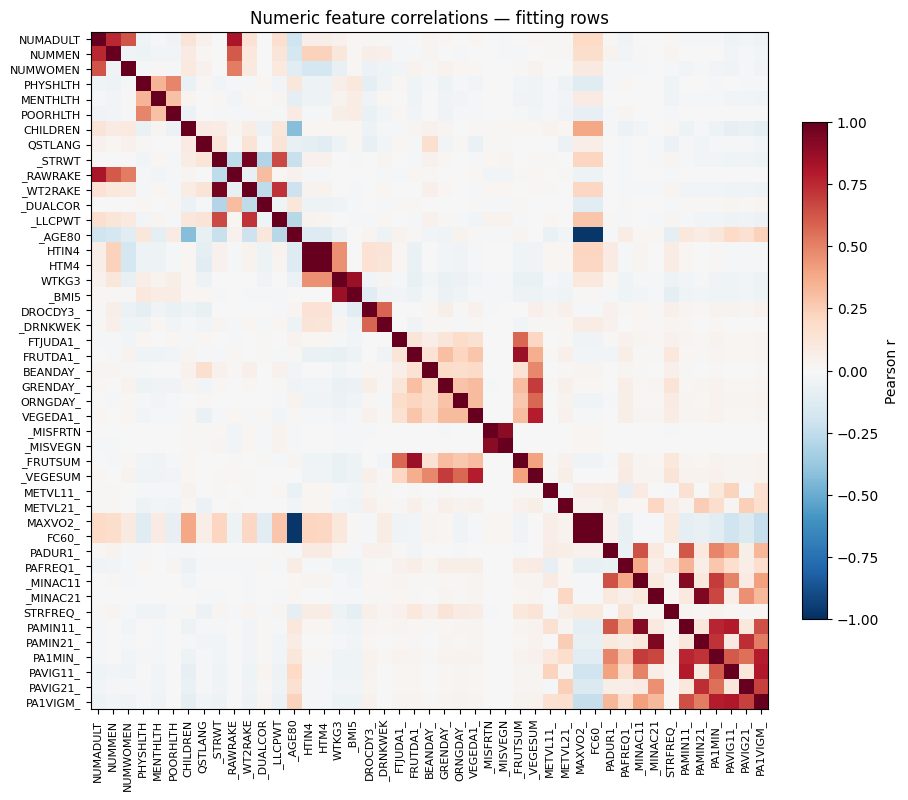

In [11]:
numeric = [k for k, (_, kind, _, _) in enumerate(prep.columns_, 1) if kind == "numeric"]
numeric_names = np.array(prep.feature_names_)[numeric]
corr = np.corrcoef(X_fit[:, numeric], rowvar=False)
fig, ax = plt.subplots(figsize=(9, 8), layout="constrained")
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set(xticks=range(len(numeric)), yticks=range(len(numeric)),
       xticklabels=numeric_names, yticklabels=numeric_names, title="Numeric feature correlations — fitting rows")
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=8)
ax.tick_params(axis="y", labelsize=8)
fig.colorbar(im, ax=ax, label="Pearson r", shrink=.7)
plt.show()

In [12]:
i, j = np.triu_indices(len(numeric), k=1)
for k in np.argsort(np.abs(corr[i, j]))[-8:][::-1]:
    print(f"{numeric_names[i[k]]} / {numeric_names[j[k]]}: r={corr[i[k], j[k]]:.3f}")

MAXVO2_ / FC60_: r=1.000
HTIN4 / HTM4: r=0.993
_AGE80 / FC60_: r=-0.969
_AGE80 / MAXVO2_: r=-0.969
_STRWT / _WT2RAKE: r=0.954
_MINAC21 / PAMIN21_: r=0.935
_MINAC11 / PAMIN11_: r=0.918
_MISFRTN / _MISVEGN: r=0.901


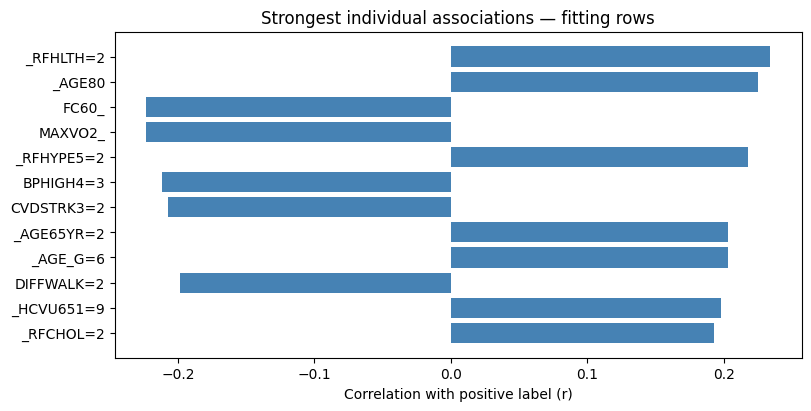

In [13]:
centered_y = y_fit - y_fit.mean()
target_r = np.zeros(X_fit.shape[1])
for start in range(1, X_fit.shape[1], 64):
    block = X_fit[:, start:start + 64].astype(float)
    scale = block.std(axis=0) * centered_y.std()
    target_r[start:start + 64] = np.divide(block.T @ centered_y / len(y_fit), scale,
                                          out=np.zeros_like(scale), where=scale > 0)
top = np.argsort(np.abs(target_r))[-12:]
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.barh(np.array(prep.feature_names_)[top], target_r[top], color="steelblue")
ax.set(xlabel="Correlation with positive label (r)", title="Strongest individual associations — fitting rows")
plt.show()

## Remove duplicates

Drop `HTIN4`- keep `HTM4` (height, r ≈ 0.994). <br>
Drop `FC60_`- keep `MAXVO2_` (r ≈ 1.000). <br>
Drop their missing flags too.

In [14]:
DROP_PAIRS = {"HTIN4": "HTM4", "FC60_": "MAXVO2_"}
reasons = {}
for drop, keep_name in DROP_PAIRS.items():
    a, b = list(numeric_names).index(drop), list(numeric_names).index(keep_name)
    assert abs(corr[a, b]) > .99
    reasons[drop] = f"r={corr[a, b]:.5f} with {keep_name}; keep {keep_name}"
    print(drop, reasons[drop])
keep = [i for i, name in enumerate(prep.feature_names_) if name.split("__")[0] not in DROP_PAIRS]
feature_names = [prep.feature_names_[i] for i in keep]
X_fit, X_tune, X_valid, X_test = [x.select(keep) for x in (X_fit, X_tune, X_valid, X_test)]
print(f"Model inputs: {len(keep)}")

HTIN4 r=0.99343 with HTM4; keep HTM4
FC60_ r=1.00000 with MAXVO2_; keep MAXVO2_
Model inputs: 3806


## Train logistic regression

MPJ's `p1.modeling.train.reg_logistic_regression` (gradient descent). Binary cross-entropy + L2 penalty.

Tune learning rate, penalty and F1 threshold. <br>
Stop on tuning loss: flat for 40 step, tolerance 1e-5, maximum 500 steps. Then evaluate.

In [ ]:
from p1.cache import cached_tuning
from p1.modeling.train import sigmoid
from p1.metrics import accuracy, f1, precision, recall

best, trials = cached_tuning(X_fit, y_fit, X_tune, y_tune, CACHE,
                            rates=(.01, .03, .1), penalties=(1e-4, 1e-3),
                            max_steps=500, patience=40, min_delta=1e-5,
                            feature_names=feature_names)
print(f"Selected: lr={best['rate']}, lambda={best['penalty']}, step={best['step']}, "
      f"threshold={best['threshold']:.4f}, early-stopped={best['stopped_early']}")

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
for trial in trials:
    ax.plot(np.arange(1, len(trial["history"]) + 1), trial["history"],
            label=f"lr={trial['rate']}, λ={trial['penalty']}")
ax.set(xlabel="Training Step (80% split)", ylabel="Tuning binary cross-entropy")
ax.legend(fontsize=8, ncol=2)
plt.show()

In [ ]:
for label, matrix, truth in [("Fit", X_fit, y_fit), ("Tune", X_tune, y_tune),
                              ("Evaluation", X_valid, y_valid)]:
    predicted = sigmoid(matrix @ best["weights"]) >= best["threshold"]
    print(f"{label}: F1={f1(truth, predicted):.4f}, accuracy={accuracy(truth, predicted):.4f}, "
          f"precision={precision(truth, predicted):.4f}, recall={recall(truth, predicted):.4f}")